# Emotion Classification with Deep Learning Models

The ML notebook uses TF-IDF, which ignores word order. Here we train two neural networks on the **padded word sequences** from Phase 1:

| Model | Idea |
|---|---|
| **Feedforward NN** | learns a word embedding, averages the embeddings of the sentence, then dense layers. Fast, but still order-blind. |
| **Bidirectional LSTM** | reads the sentence left-to-right and right-to-left, so it can use word order and context ("not happy", "happy to see you go"). |

Both models use the **class weights** from Phase 1 (`label_mapping.json`) so that rare emotions (*surprise*, *love*) count more in the loss, and both are judged mainly on **macro-F1**. Training uses the train split, the validation split is used for **early stopping**, and the test split is used only once at the end.

The trained models are **saved to `../models/dl/`** for the web app.

## Imports

In [1]:
import json
import os
import shutil
import sys

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from keras.callbacks import EarlyStopping
from keras.layers import (LSTM, Bidirectional, Dense, Dropout, Embedding,
                          GlobalAveragePooling1D, Input)
from keras.models import Sequential
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             top_k_accuracy_score)

DATA_DIR = "../data/processed"
MODEL_DIR = "../models/dl"
PLOT_DIR = "../plots/dl"
RESULTS_DIR = "../results"
for d in (MODEL_DIR, PLOT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.22.0-rc1 | Keras 3.16.0.dev2026112503


## Load datasets
The data comes from **Phase 1** (the DS project). Phase 1 cleaned the CARER emotion dataset and saved every split in `../data/processed/`:

| File | What it contains | Used here for |
|---|---|---|
| `train_clean.csv`, `val_clean.csv`, `test_clean.csv` | cleaned text, label, `is_length_outlier` flag | checking labels, error analysis |
| `seq_train.npy`, `seq_val.npy`, `seq_test.npy` | padded word-id sequences built from the clean text | model input |
| `y_train.npy`, `y_val.npy`, `y_test.npy` | label ids | targets |
| `vocab.json`, `label_mapping.json` | vocabulary, label ids and class weights | settings |

Rows after cleaning: **15,923 train / 1,993 val / 2,000 test**.

In [2]:
train_df = pd.read_csv(f"{DATA_DIR}/train_clean.csv")
val_df = pd.read_csv(f"{DATA_DIR}/val_clean.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test_clean.csv")
print(f"Train: {train_df.shape}, Val: {val_df.shape}, Test: {test_df.shape}")
train_df.head()

Train: (15923, 3), Val: (1993, 3), Test: (2000, 3)


,text,label,is_length_outlier
0,i didnt feel humiliated,sadness,False
1,i can go from feeling so hopeless to so damned...,sadness,False
2,im grabbing a minute to post i feel greedy wrong,anger,False
3,i am ever feeling nostalgic about the fireplac...,love,False
4,i am feeling grouchy,anger,False


## Labels and class weights
The label ids come from Phase 1: anger = 0, fear = 1, joy = 2, love = 3, sadness = 4, surprise = 5. Phase 1 also computed **balanced class weights** (`n_samples / (n_classes * n_class_samples)`): *surprise* gets a weight of about 4.7, *joy* about 0.5.

In [3]:
with open(f"{DATA_DIR}/label_mapping.json") as f:
    label_map = json.load(f)

label2id = label_map["label2id"]
CLASSES = sorted(label2id, key=label2id.get)
num_classes = len(CLASSES)
class_weight = {int(k): float(v) for k, v in label_map["class_weights"].items()}

print("Classes:", CLASSES)
print("Class weights:", {CLASSES[k]: round(v, 2) for k, v in class_weight.items()})

Classes: ['anger', 'fear', 'joy', 'love', 'sadness', 'surprise']
Class weights: {'anger': 1.23, 'fear': 1.38, 'joy': 0.5, 'love': 2.07, 'sadness': 0.57, 'surprise': 4.71}


## Padded sequences
Phase 1 turned the clean text into padded sequences (`seq_*.npy`) with a vocabulary of 10,000 words built on the **train split only** (0 = padding, 1 = unknown word). Sequences are padded and truncated at the front to 52 tokens, which covers 99% of the texts.

In [4]:
with open(f"{DATA_DIR}/vocab.json") as f:
    vocab_info = json.load(f)

MAX_WORDS = vocab_info["max_words"]
MAX_LEN = vocab_info["max_len"]

X_train = np.load(f"{DATA_DIR}/seq_train.npy")
X_val = np.load(f"{DATA_DIR}/seq_val.npy")
X_test = np.load(f"{DATA_DIR}/seq_test.npy")
y_train = np.load(f"{DATA_DIR}/y_train.npy")
y_val = np.load(f"{DATA_DIR}/y_val.npy")
y_test = np.load(f"{DATA_DIR}/y_test.npy")

for df, y in [(train_df, y_train), (val_df, y_val), (test_df, y_test)]:
    assert (df["label"].map(label2id).values == y).all()

print(f"MAX_WORDS: {MAX_WORDS}, MAX_LEN: {MAX_LEN}")
print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

MAX_WORDS: 10000, MAX_LEN: 52
Train: (15923, 52), Val: (1993, 52), Test: (2000, 52)


## Model 1: Feedforward NN
Embedding (128-d) → global average pooling → Dense(256) → Dropout(0.3) → Dense(128) → Dropout(0.2) → softmax over 6 emotions.

Training: Adam, sparse categorical cross-entropy weighted by class, batch size 32, up to 15 epochs with **early stopping** on validation loss (patience 3, best weights restored).

In [5]:
def early_stop():
    return EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

model_ffnn = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(MAX_WORDS, 128),
    GlobalAveragePooling1D(),
    Dense(256, activation="relu"),
    Dropout(0.3),
    Dense(128, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax"),
], name="ffnn")
model_ffnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_ffnn.summary()

history_ffnn = model_ffnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15, batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stop()],
    verbose=1,
)

Model: "ffnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 52, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,346,694 (5.14 MB)

 Trainable params: 1,346,694 (5.14 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 13s 21ms/step - accuracy: 0.1741 - loss: 1.7841 - val_accuracy: 0.1515 - val_loss: 1.7540
Epoch 2/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.5685 - loss: 1.1212 - val_accuracy: 0.7657 - val_loss: 0.6908
Epoch 3/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8700 - loss: 0.3773 - val_accuracy: 0.8761 - val_loss: 0.4128
Epoch 4/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9182 - loss: 0.2288 - val_accuracy: 0.8665 - val_loss: 0.4599
Epoch 5/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9273 - loss: 0.1988 - val_accuracy: 0.8630 - val_loss: 0.4782
Epoch 6/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.9513 - loss: 0.1359 - val_accuracy: 0.8550 - val_loss: 0.5354


## Model 2: Bidirectional LSTM
Embedding (128-d) → Bidirectional LSTM (128 units each way) → Dense(128) → Dropout(0.3) → softmax. Same training setup as above.

In [6]:
model_lstm = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(MAX_WORDS, 128),
    Bidirectional(LSTM(128)),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(num_classes, activation="softmax"),
], name="bilstm")
model_lstm.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_lstm.summary()

history_lstm = model_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15, batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stop()],
    verbose=1,
)

Model: "bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 52, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256)            │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,576,838 (6.02 MB)

 Trainable params: 1,576,838 (6.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step - accuracy: 0.5133 - loss: 1.2738 - val_accuracy: 0.8665 - val_loss: 0.4284
Epoch 2/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 32s 63ms/step - accuracy: 0.9052 - loss: 0.2806 - val_accuracy: 0.8620 - val_loss: 0.4658
Epoch 3/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 32s 64ms/step - accuracy: 0.9424 - loss: 0.1524 - val_accuracy: 0.9057 - val_loss: 0.3042
Epoch 4/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 32s 64ms/step - accuracy: 0.9594 - loss: 0.1267 - val_accuracy: 0.9072 - val_loss: 0.3210
Epoch 5/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 32s 64ms/step - accuracy: 0.9678 - loss: 0.0882 - val_accuracy: 0.8896 - val_loss: 0.4891
Epoch 6/15
498/498 ━━━━━━━━━━━━━━━━━━━━ 32s 64ms/step - accuracy: 0.9781 - loss: 0.0640 - val_accuracy: 0.9167 - val_loss: 0.3147


## Training curves
If validation loss starts rising while training loss keeps falling, the model is overfitting; early stopping keeps the weights from the best epoch.

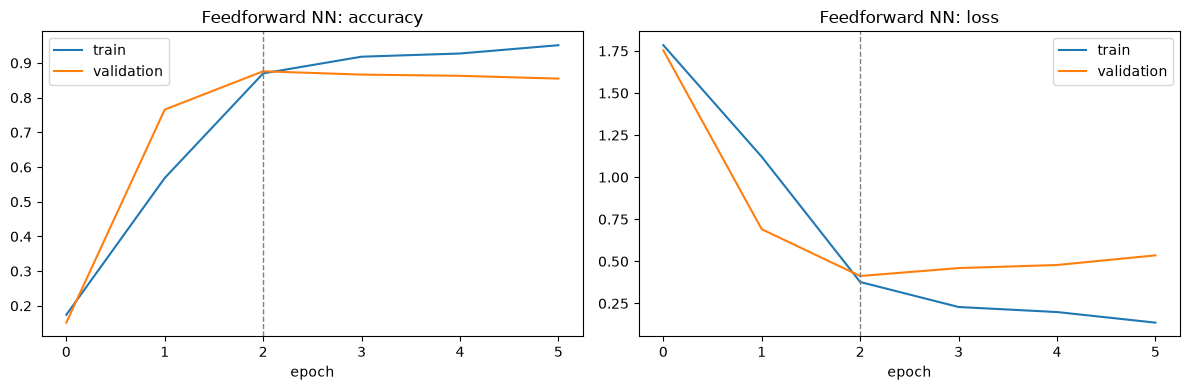

best epoch: 3 (val_loss 0.413, val_acc 0.876)


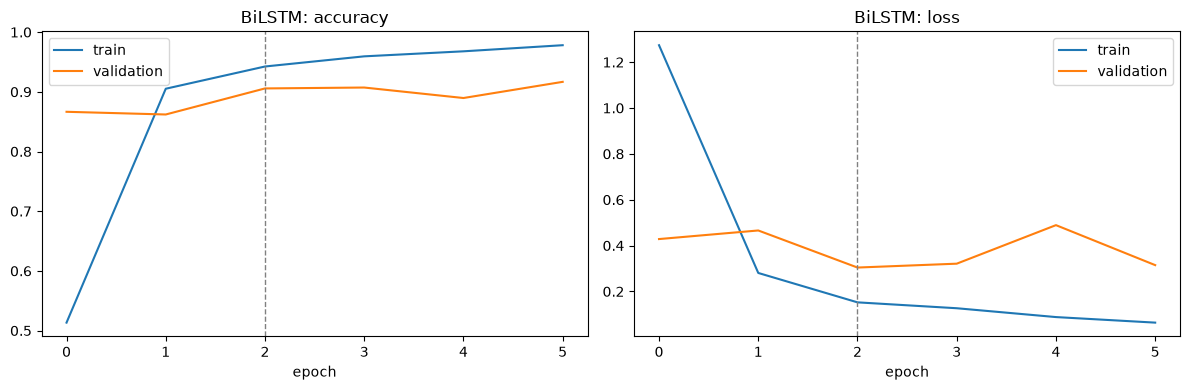

best epoch: 3 (val_loss 0.304, val_acc 0.906)


In [7]:
def plot_history(history, title, fname):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="validation")
    axes[0].set_title(f"{title}: accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h["loss"], label="train"); axes[1].plot(h["val_loss"], label="validation")
    axes[1].set_title(f"{title}: loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
    best = int(np.argmin(h["val_loss"]))
    for ax in axes:
        ax.axvline(best, color="grey", ls="--", lw=1)
    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"best epoch: {best + 1} (val_loss {h['val_loss'][best]:.3f}, val_acc {h['val_accuracy'][best]:.3f})")

plot_history(history_ffnn, "Feedforward NN", "ffnn_training_curves.png")
plot_history(history_lstm, "BiLSTM", "lstm_training_curves.png")

## Evaluation on the test set
Same metrics as the ML notebook, so the results can be compared directly: accuracy, **macro-F1**, macro precision/recall, weighted F1, ROC-AUC (one-vs-rest, macro), top-3 accuracy, per-class report and confusion matrix.

In [8]:
def evaluate_dl(model, X, y, name, fname):
    y_prob = model.predict(X, verbose=0)
    y_pred = y_prob.argmax(axis=1)

    m = {
        "accuracy": accuracy_score(y, y_pred),
        "macro_precision": precision_score(y, y_pred, average="macro"),
        "macro_recall": recall_score(y, y_pred, average="macro"),
        "macro_f1": f1_score(y, y_pred, average="macro"),
        "weighted_f1": f1_score(y, y_pred, average="weighted"),
        "roc_auc_ovr": roc_auc_score(y, y_prob, multi_class="ovr", average="macro"),
        "top3_accuracy": top_k_accuracy_score(y, y_prob, k=3, labels=range(num_classes)),
    }
    report = classification_report(y, y_pred, labels=range(num_classes), target_names=CLASSES, output_dict=True)
    m["per_class_f1"] = {c: report[c]["f1-score"] for c in CLASSES}
    m["per_class_recall"] = {c: report[c]["recall"] for c in CLASSES}

    print(f"\n=== {name} ===")
    print("  ".join(f"{k}: {v:.3f}" for k, v in m.items() if not isinstance(v, dict)))
    print(classification_report(y, y_pred, labels=range(num_classes), target_names=CLASSES, digits=3))

    cm = confusion_matrix(y, y_pred, labels=range(num_classes))
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
    axes[0].set_title(f"{name}: counts")
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
                xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], vmin=0, vmax=1)
    axes[1].set_title(f"{name}: row-normalised (recall)")
    for ax in axes:
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"{PLOT_DIR}/{fname}", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    return m, y_pred


=== Feedforward NN ===
accuracy: 0.875  macro_precision: 0.814  macro_recall: 0.873  macro_f1: 0.835  weighted_f1: 0.878  roc_auc_ovr: 0.977  top3_accuracy: 0.990
              precision    recall  f1-score   support

       anger      0.890     0.825     0.857       275
        fear      0.879     0.844     0.861       224
         joy      0.940     0.881     0.909       695
        love      0.671     0.937     0.782       159
     sadness      0.923     0.888     0.905       581
    surprise      0.582     0.864     0.695        66

    accuracy                          0.875      2000
   macro avg      0.814     0.873     0.835      2000
weighted avg      0.888     0.875     0.878      2000



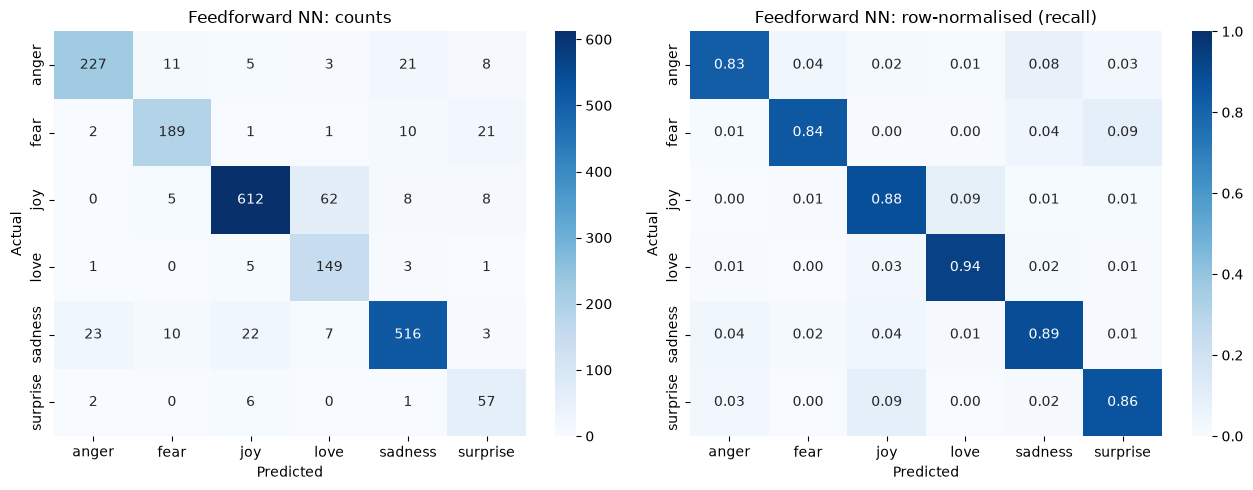


=== BiLSTM ===
accuracy: 0.901  macro_precision: 0.847  macro_recall: 0.899  macro_f1: 0.869  weighted_f1: 0.904  roc_auc_ovr: 0.990  top3_accuracy: 0.992
              precision    recall  f1-score   support

       anger      0.858     0.880     0.869       275
        fear      0.878     0.866     0.872       224
         joy      0.970     0.888     0.927       695
        love      0.718     0.931     0.811       159
     sadness      0.949     0.935     0.942       581
    surprise      0.711     0.894     0.792        66

    accuracy                          0.901      2000
   macro avg      0.847     0.899     0.869      2000
weighted avg      0.910     0.901     0.904      2000



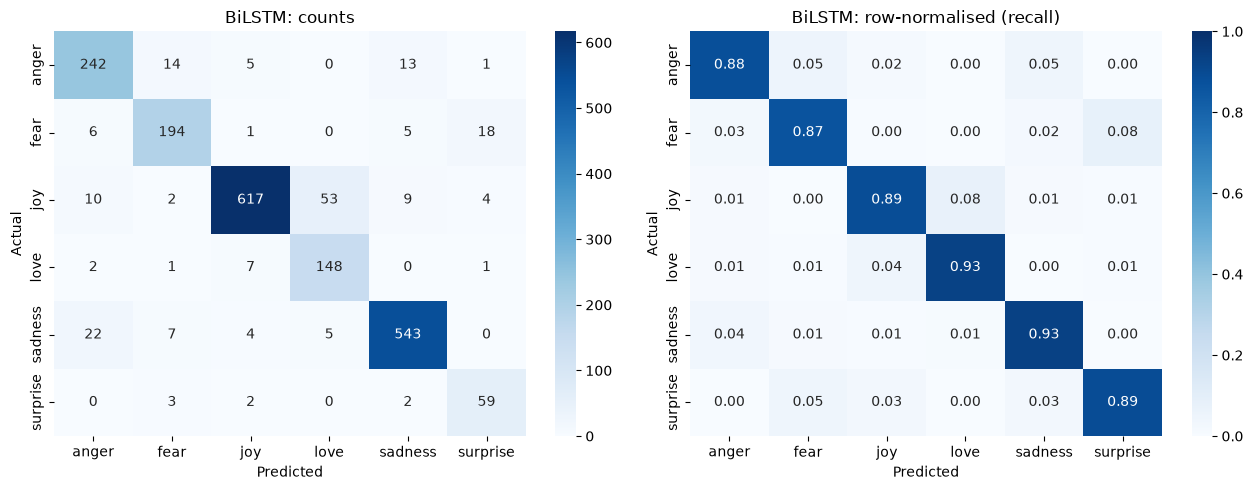

In [9]:
metrics, predictions = {}, {}
metrics["Feedforward NN"], predictions["Feedforward NN"] = evaluate_dl(model_ffnn, X_test, y_test, "Feedforward NN", "ffnn_confusion_matrix.png")
metrics["BiLSTM"], predictions["BiLSTM"] = evaluate_dl(model_lstm, X_test, y_test, "BiLSTM", "lstm_confusion_matrix.png")

metrics["Feedforward NN"]["epochs_trained"] = len(history_ffnn.history["loss"])
metrics["BiLSTM"]["epochs_trained"] = len(history_lstm.history["loss"])

## Comparison

,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,roc_auc_ovr,top3_accuracy
Feedforward NN,0.875,0.835,0.814,0.873,0.878,0.977,0.990
BiLSTM,0.901,0.869,0.847,0.899,0.904,0.990,0.992


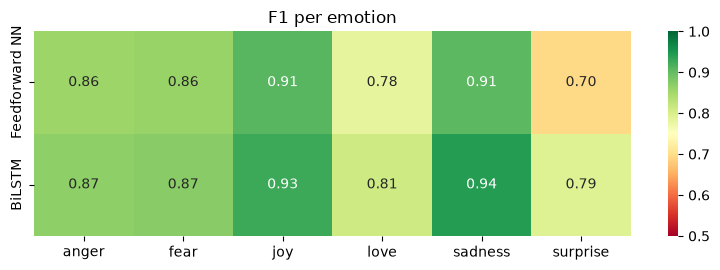

In [10]:
cols = ["accuracy", "macro_f1", "macro_precision", "macro_recall", "weighted_f1", "roc_auc_ovr", "top3_accuracy"]
summary = pd.DataFrame(metrics).T[cols].astype(float)
display(summary.style.format("{:.3f}"))

per_class = pd.DataFrame({n: metrics[n]["per_class_f1"] for n in metrics}).T
plt.figure(figsize=(8, 2.8))
sns.heatmap(per_class, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0.5, vmax=1)
plt.title("F1 per emotion")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/dl_per_class_f1.png", dpi=150, bbox_inches="tight")
plt.show()

## Error analysis (BiLSTM)

In [11]:
err = test_df[["text", "label"]].copy()
err["predicted"] = [CLASSES[i] for i in predictions["BiLSTM"]]
wrong = err[err["label"] != err["predicted"]]
print(f"{len(wrong)} of {len(err)} misclassified ({len(wrong) / len(err):.1%})\n")
pairs = wrong.groupby(["label", "predicted"]).size().sort_values(ascending=False).head(8)
print(pairs.to_string())

pd.set_option("display.max_colwidth", 120)
for actual, pred in pairs.index[:3]:
    print(f"\n--- actual: {actual}, predicted: {pred} ---")
    for t in wrong[(wrong.label == actual) & (wrong.predicted == pred)]["text"].head(3):
        print("  •", t)

197 of 2000 misclassified (9.8%)

label    predicted
joy      love         53
sadness  anger        22
fear     surprise     18
anger    fear         14
         sadness      13
joy      anger        10
         sadness       9
sadness  fear          7

--- actual: joy, predicted: love ---
  • i feel like i am in paradise kissing those sweet lips make me feel like i dive into a magical world of love
  • i realized what i am passionate about helping women feel accepted and appreciated
  • i believe that feeling accepted in a non judgemental way can be healing

--- actual: sadness, predicted: anger ---
  • i hope everyone can help with charity work without feeling stressed about such things
  • i will nolonger tell anybody how i feel or what im thinking cause all it seems to do is get me more hated than i already am
  • i do feel stressed

--- actual: fear, predicted: surprise ---
  • i feel kinda weird when andrea tries to talk to me about chris
  • i feel strange talking about less ser

## Save models
The models are saved in the native Keras format (`.keras`). A copy of `vocab.json` goes next to them, because the app needs the same word ids to turn new text into a sequence.

In [12]:
model_ffnn.save(f"{MODEL_DIR}/ffnn.keras")
model_lstm.save(f"{MODEL_DIR}/lstm.keras")
shutil.copy(f"{DATA_DIR}/vocab.json", f"{MODEL_DIR}/vocab.json")
with open(f"{MODEL_DIR}/metadata.json", "w") as f:
    json.dump({"input": "padded sequences, see app/voxaid_core.py: clean_text + to_sequence",
               "classes": CLASSES, "max_len": MAX_LEN, "tensorflow_version": tf.__version__}, f, indent=2)

for fn in ["ffnn.keras", "lstm.keras"]:
    print(f"saved {MODEL_DIR}/{fn}: {os.path.getsize(f'{MODEL_DIR}/{fn}') / 1e6:.1f} MB")

saved ../models/dl/ffnn.keras: 16.2 MB
saved ../models/dl/lstm.keras: 19.0 MB


In [13]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {k: to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    return o

with open(f"{RESULTS_DIR}/dl_metrics.json", "w") as f:
    json.dump(to_jsonable(metrics), f, indent=2)
print("Metrics saved to ../results/dl_metrics.json")

Metrics saved to ../results/dl_metrics.json


### Sanity check: reload the saved LSTM and predict new sentences with the app's preprocessing

In [14]:
sys.path.insert(0, "../app")
from voxaid_core import clean_text, to_sequence

reloaded = keras.models.load_model(f"{MODEL_DIR}/lstm.keras")
assert np.allclose(reloaded.predict(X_test[:5], verbose=0), model_lstm.predict(X_test[:5], verbose=0), atol=1e-5)

samples = ["I can't believe I finally got the job, I'm so happy!",
           "I'm really worried about my exam tomorrow",
           "Why does everyone keep ignoring me, it's so annoying",
           "I miss my grandmother so much",
           "Wow, I did not expect that at all!",
           "I feel so lucky to have you in my life"]
for s in samples:
    p = reloaded.predict(to_sequence(clean_text(s)), verbose=0)[0]
    top = p.argsort()[::-1][:2]
    print(f"{s:55s} -> {CLASSES[top[0]]:8s} ({p[top[0]]:.2f}), then {CLASSES[top[1]]} ({p[top[1]]:.2f})")

I can't believe I finally got the job, I'm so happy!    -> joy      (0.77), then sadness (0.14)
I'm really worried about my exam tomorrow               -> fear     (0.75), then anger (0.10)
Why does everyone keep ignoring me, it's so annoying    -> sadness  (0.65), then joy (0.18)
I miss my grandmother so much                           -> sadness  (0.31), then anger (0.28)
Wow, I did not expect that at all!                      -> anger    (0.54), then fear (0.16)
I feel so lucky to have you in my life                  -> joy      (1.00), then anger (0.00)


## Conclusion
- Compare the table above with `results/ml_metrics.json` (or run `model_comparison.ipynb`). In the first version, without class weights, the BiLSTM was the most accurate model (accuracy 0.921), ahead of the Feedforward NN (0.845) and the linear ML models (about 0.90), because it reads word order.
- The Feedforward NN averages embeddings, so like TF-IDF it ignores word order; it is the weakest model here.
- Class weights should lift recall on *surprise* and *love*; the per-class table shows how much.
- The LSTM is larger and slower than the linear models and needs TensorFlow, which makes the web app heavier to deploy. That trade-off is discussed in `model_comparison.ipynb` and the README.